# Marketing channel comparison &mdash; statistical analysis

**Dataset:** `criteo/criteo-attribution-dataset` &mdash; real ad-serving logs
**Author:** Nnanyelugo Ahukannah

This notebook walks the analysis end to end. It reads the extract that
`fetch_dataset.py` streamed from Hugging Face and re-runs every test, so the
numbers here are produced live rather than pasted.

The question throughout: **which campaign differences are real, and which are
merely detectable?** With tens of thousands of impressions per campaign those are
very different things, and separating them is what the lab is about.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
print("interpreter:", sys.executable)
assert "bootcamp-env" in sys.executable, "wrong kernel - expected bootcamp-env"

interpreter: /opt/homebrew/Caskroom/miniconda/base/envs/bootcamp-env/bin/python


## Step 2 &mdash; load and explore

In [2]:
import pandas as pd, numpy as np
from marketing_data import load_criteo, analysis_frame, group_summary, wilson_ci

df = load_criteo()
print(f"rows {len(df):,} | campaigns {df.campaign.nunique():,} | "
      f"CTR {df.click.mean():.2%} | CVR {df.conversion.mean():.2%}")
print(f"rows dropped in cleaning: {df.attrs['rows_dropped']}")
sub = analysis_frame(df)
print(f"\nanalysis set: {sub.group.nunique()} campaigns, {len(sub):,} impressions")

rows 400,000 | campaigns 661 | CTR 34.48% | CVR 4.95%
rows dropped in cleaning: 0

analysis set: 6 campaigns, 68,273 impressions


### Step 3 &mdash; key marketing metrics per campaign

In [3]:
g = group_summary(sub)
g["cvr_ci"] = [f"[{wilson_ci(int(r.conversions), int(r.impressions))[0]*100:.2f}, "
               f"{wilson_ci(int(r.conversions), int(r.impressions))[1]*100:.2f}]"
               for r in g.itertuples()]
g[["impressions","clicks","conversions","ctr_pct","cvr_pct","cvr_ci","total_cost","cpa"]].round(4)

,impressions,clicks,conversions,ctr_pct,cvr_pct,cvr_ci,total_cost,cpa
group,,,,,,,,
Campaign A,21680,7617,816,35.1338,3.7638,"[3.52, 4.03]",1.4415,0.0018
Campaign B,14802,6183,1226,41.7714,8.2827,"[7.85, 8.74]",3.7631,0.0031
Campaign C,10157,2731,207,26.8879,2.0380,"[1.78, 2.33]",2.0270,0.0098
Campaign D,9755,2537,230,26.0072,2.3578,"[2.07, 2.68]",4.6149,0.0201
Campaign E,6071,2403,467,39.5816,7.6923,"[7.05, 8.39]",1.8126,0.0039
Campaign F,5808,2370,272,40.8058,4.6832,"[4.17, 5.26]",1.2491,0.0046


In [4]:
print(f"CPA spread: {g.cpa.max()/g.cpa.min():.1f}x  "
      f"({g.cpa.idxmin()} cheapest at {g.cpa.min():.4f}, {g.cpa.idxmax()} dearest at {g.cpa.max():.4f})")
print("Cost figures are Criteo's anonymised units - ratios are meaningful, the absolute numbers are not money.")

CPA spread: 11.4x  (Campaign A cheapest at 0.0018, Campaign D dearest at 0.0201)
Cost figures are Criteo's anonymised units - ratios are meaningful, the absolute numbers are not money.


## Steps 4 & 5 &mdash; pairwise tests and effect sizes

Two families, because the metrics are different kinds of thing: a continuous,
right-skewed cost measurement (Welch's t-test, unequal variances) and a binary
conversion outcome (Fisher's exact test).

In [5]:
from statistical_analysis import ttest_pairs, fisher_pairs, correct

tt = correct(ttest_pairs(sub), "Cost per impression (Welch's t-test)")
fi = correct(fisher_pairs(sub), "Conversion rate (Fisher's exact test)")


Cost per impression (Welch's t-test): 15 comparisons at alpha=0.05
  significant uncorrected       14/15
  significant after Bonferroni  14/15   (threshold 0.00333)
  significant after BH (FDR)    14/15
  results withdrawn by Bonferroni 0, by BH 0

Conversion rate (Fisher's exact test): 15 comparisons at alpha=0.05
  significant uncorrected       13/15
  significant after Bonferroni  13/15   (threshold 0.00333)
  significant after BH (FDR)    13/15
  results withdrawn by Bonferroni 0, by BH 0


In [6]:
tt[["group_a","group_b","pct_diff","p_raw","p_bonferroni","p_bh","cohens_d","effect","sig_bh"]].round(5)

,group_a,group_b,pct_diff,p_raw,p_bonferroni,p_bh,cohens_d,effect,sig_bh
0,Campaign A,Campaign B,-73.84681,0.00000,0.00000,0.00000,-0.32715,small,True
1,Campaign A,Campaign C,-66.68363,0.00000,0.00000,0.00000,-0.41814,small,True
2,Campaign A,Campaign D,-85.94526,0.00000,0.00000,0.00000,-0.73280,medium,True
3,Campaign A,Campaign E,-77.73106,0.00000,0.00000,0.00000,-0.48946,small,True
4,Campaign A,Campaign F,-69.08299,0.00000,0.00000,0.00000,-0.43843,small,True
5,Campaign B,Campaign C,27.38931,0.00000,0.00000,0.00000,0.07624,negligible,True
6,Campaign B,Campaign D,-46.25996,0.00000,0.00000,0.00000,-0.24698,small,True
7,Campaign B,Campaign E,-14.85191,0.00115,0.01723,0.00123,-0.05090,negligible,True
8,Campaign B,Campaign F,18.21506,0.00015,0.00232,0.00018,0.04979,negligible,True
9,Campaign C,Campaign D,-57.81432,0.00000,0.00000,0.00000,-0.37681,small,True


In [7]:
fi[["group_a","group_b","cvr_a_pct","cvr_b_pct","relative_lift_pct","odds_ratio",
    "p_raw","p_bh","sig_bh"]].round(4)

,group_a,group_b,cvr_a_pct,cvr_b_pct,relative_lift_pct,odds_ratio,p_raw,p_bh,sig_bh
0,Campaign A,Campaign B,3.7638,8.2827,-54.5576,0.4331,0.0000,0.0000,True
1,Campaign A,Campaign C,3.7638,2.0380,84.6826,1.8799,0.0000,0.0000,True
2,Campaign A,Campaign D,3.7638,2.3578,59.6358,1.6197,0.0000,0.0000,True
3,Campaign A,Campaign E,3.7638,7.6923,-51.0701,0.4693,0.0000,0.0000,True
4,Campaign A,Campaign F,3.7638,4.6832,-19.6310,0.7960,0.0017,0.0019,True
5,Campaign B,Campaign C,8.2827,2.0380,306.4107,4.3408,0.0000,0.0000,True
6,Campaign B,Campaign D,8.2827,2.3578,251.2930,3.7399,0.0000,0.0000,True
7,Campaign B,Campaign E,8.2827,7.6923,7.6746,1.0837,0.1628,0.1628,False
8,Campaign B,Campaign F,8.2827,4.6832,76.8592,1.8380,0.0000,0.0000,True
9,Campaign C,Campaign D,2.0380,2.3578,-13.5621,0.8616,0.1336,0.1431,False


### The finding that matters

Almost everything is significant. That is a fact about the sample size, not about
the campaigns.

In [8]:
negl = tt[(tt.sig_bh) & (tt.cohens_d.abs() < 0.2)]
print(f"cost pairs significant after BH:                 {int(tt.sig_bh.sum())}/15")
print(f"  ...of those, with a NEGLIGIBLE effect size:    {len(negl)}")
print(f"largest |Cohen's d| anywhere in the set:         {tt.cohens_d.abs().max():.3f}")
print()
print("Pairs that are NOT significantly different - as useful as the ones that are:")
for r in fi[~fi.sig_bh].itertuples():
    print(f"  {r.group_a} vs {r.group_b}: {r.cvr_a_pct:.2f}% vs {r.cvr_b_pct:.2f}%  (p={r.p_raw:.3f})")

cost pairs significant after BH:                 14/15
  ...of those, with a NEGLIGIBLE effect size:    6
largest |Cohen's d| anywhere in the set:         0.733

Pairs that are NOT significantly different - as useful as the ones that are:
  Campaign B vs Campaign E: 8.28% vs 7.69%  (p=0.163)
  Campaign C vs Campaign D: 2.04% vs 2.36%  (p=0.134)


## Step 6 &mdash; multiple comparisons correction

Fifteen comparisons per family. Corrected within each family, not across both:
they answer different questions and a marketer acts on them separately.

On the full sample the correction withdraws nothing, because the p-values are at
machine zero. Reporting that alone would hide the mechanism, so the same tests
are repeated at a realistic pilot size.

In [9]:
from statistical_analysis import correction_bites_demo
demo = correction_bites_demo(sub)


DOES THE CORRECTION EVER BITE? - same tests, 400 impressions per campaign
  subsample size               2,400 impressions (6 campaigns x 400)
  significant uncorrected        7/15
  significant after BH           6/15
  significant after Bonferroni   4/15
  withdrawn by Bonferroni      3
      Campaign A vs Campaign D: p=0.0172 -> not significant at the corrected threshold 0.00333
      Campaign B vs Campaign F: p=0.0343 -> not significant at the corrected threshold 0.00333
      Campaign E vs Campaign F: p=0.0175 -> not significant at the corrected threshold 0.00333

  This is what the correction is for: at pilot scale several pairs look
  significant on their own and stop looking significant once you account
  for having asked the question fifteen times.


## Step 7 &mdash; power analysis

In [10]:
from power_analysis import required_n_continuous, required_n_conversion, achieved_power
baseline = float(g.conversions.sum() / g.impressions.sum())
print(f"pooled baseline conversion rate: {baseline:.4%}\n")
required_n_conversion(baseline).round(4)

pooled baseline conversion rate: 4.7134%



,relative_lift,baseline_cvr_pct,target_cvr_pct,cohens_h,n_per_arm_uncorrected,n_per_arm_bonferroni
0,+5%,4.7134,4.9491,0.0110,129932,236136
1,+10%,4.7134,5.1848,0.0217,33221,60375
2,+20%,4.7134,5.6561,0.0426,8667,15751
3,+30%,4.7134,6.1275,0.0626,4009,7285
4,+50%,4.7134,7.0701,0.1006,1552,2821
5,+100%,4.7134,9.4269,0.1865,452,821


In [11]:
req = required_n_continuous()
print("continuous metric, impressions per group for 80% power:")
print(req.to_string(index=False))
print(f"\nsmallest campaign has {int(g.impressions.min()):,} impressions; "
      f"detecting a small effect (d=0.2) needs "
      f"{int(req.loc[req.effect_d==0.2,'n_per_group_bonferroni'].iloc[0]):,}. Adequate.")

continuous metric, impressions per group for 80% power:
 effect_d      label  n_per_group_uncorrected  n_per_group_bonferroni
     0.05 negligible                     6281                   11414
     0.10 negligible                     1571                    2856
     0.20      small                      394                     716
     0.30      small                      176                     320
     0.50     medium                       64                     117
     0.80      large                       26                      47

smallest campaign has 5,808 impressions; detecting a small effect (d=0.2) needs 716. Adequate.


## Figures

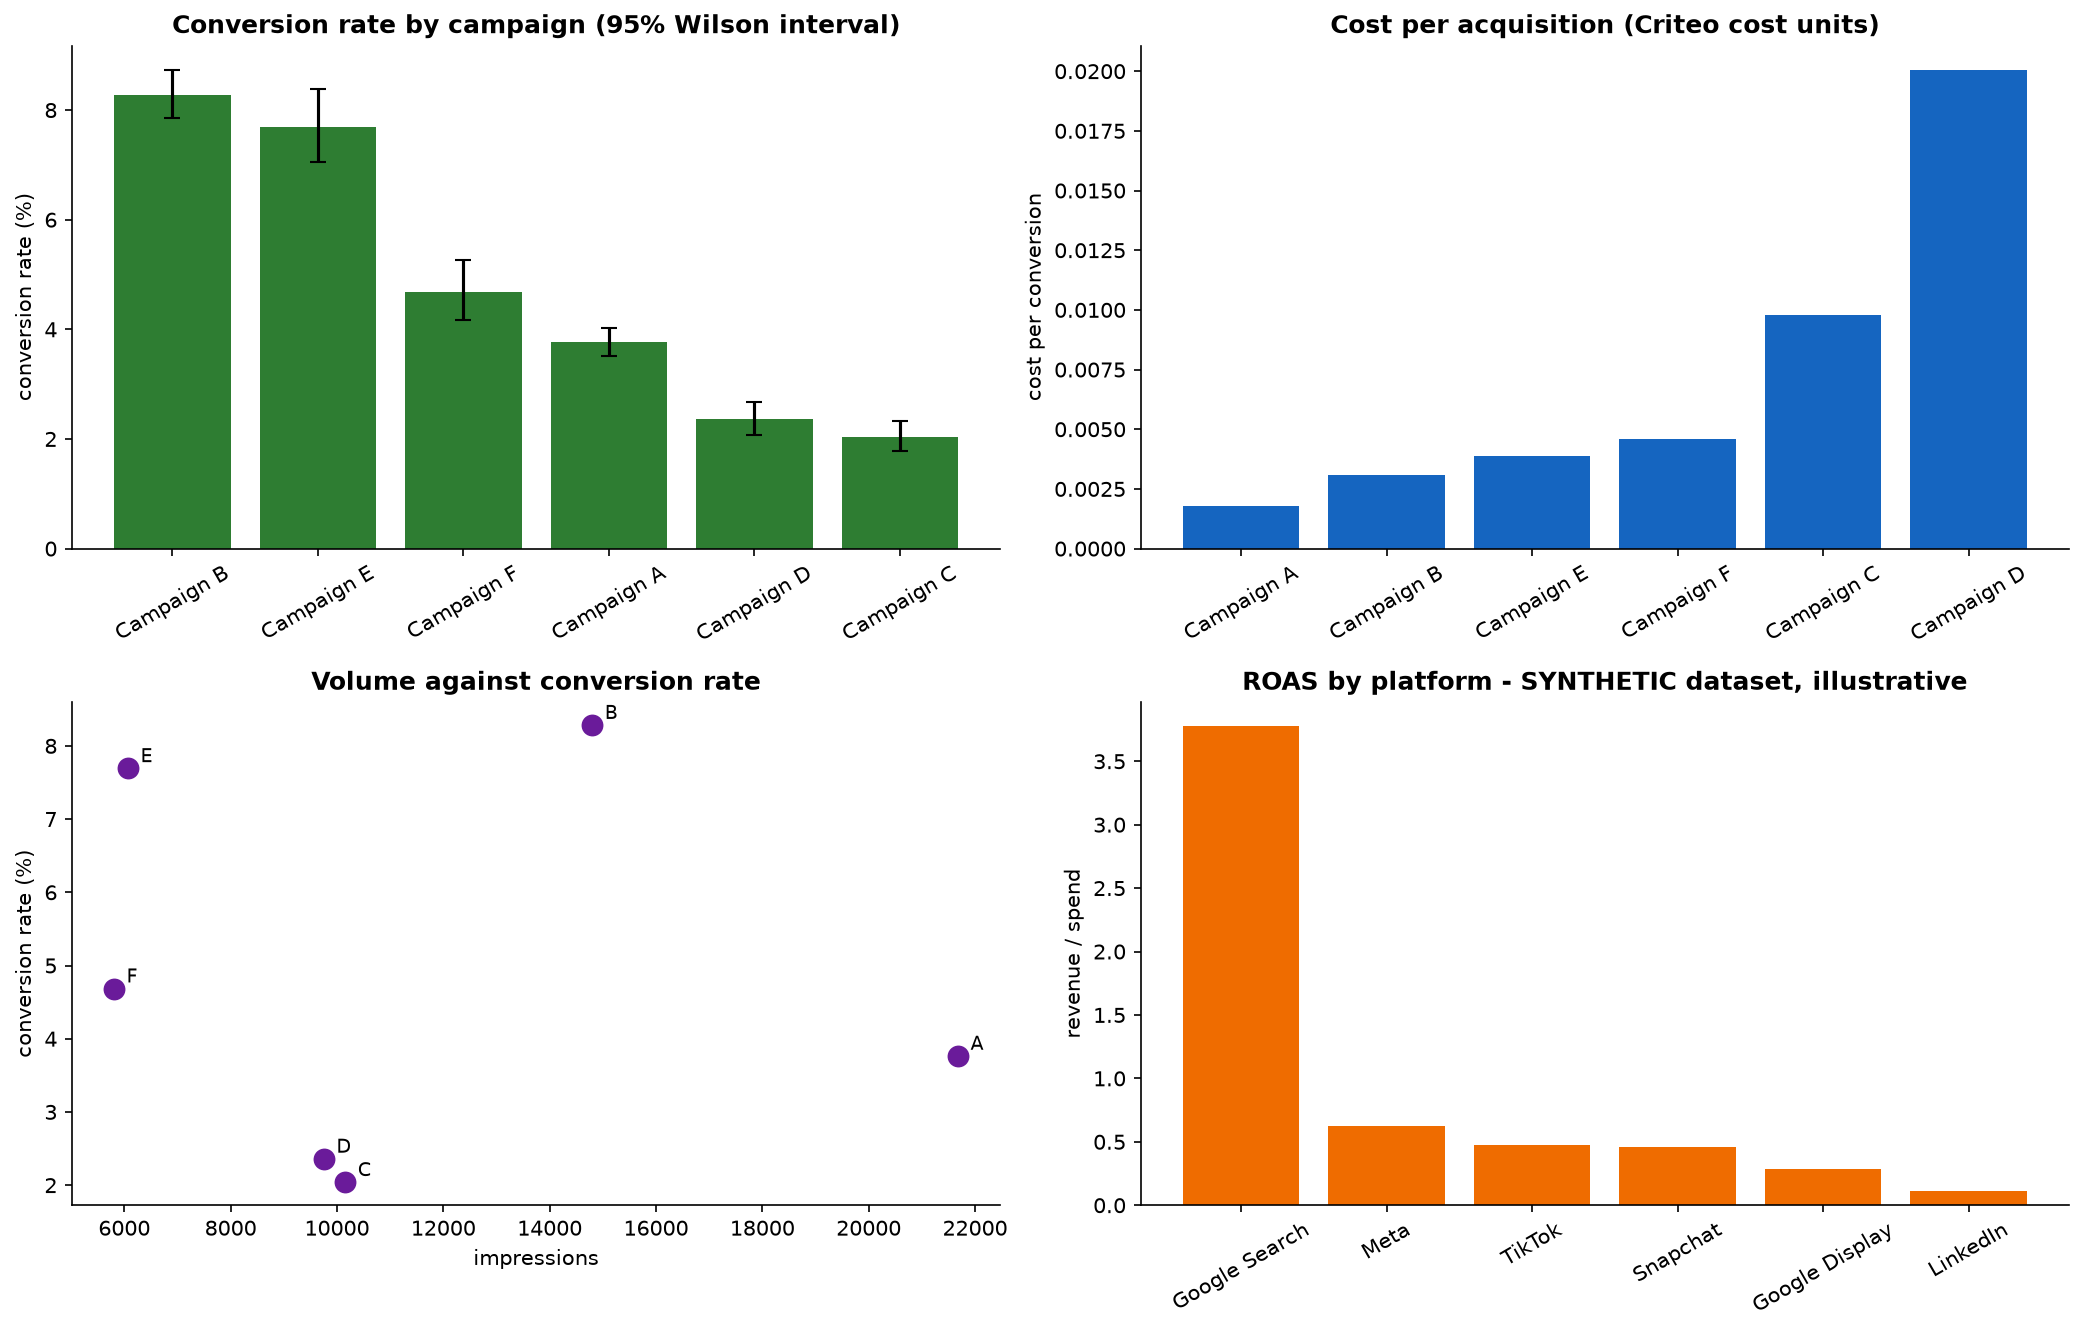

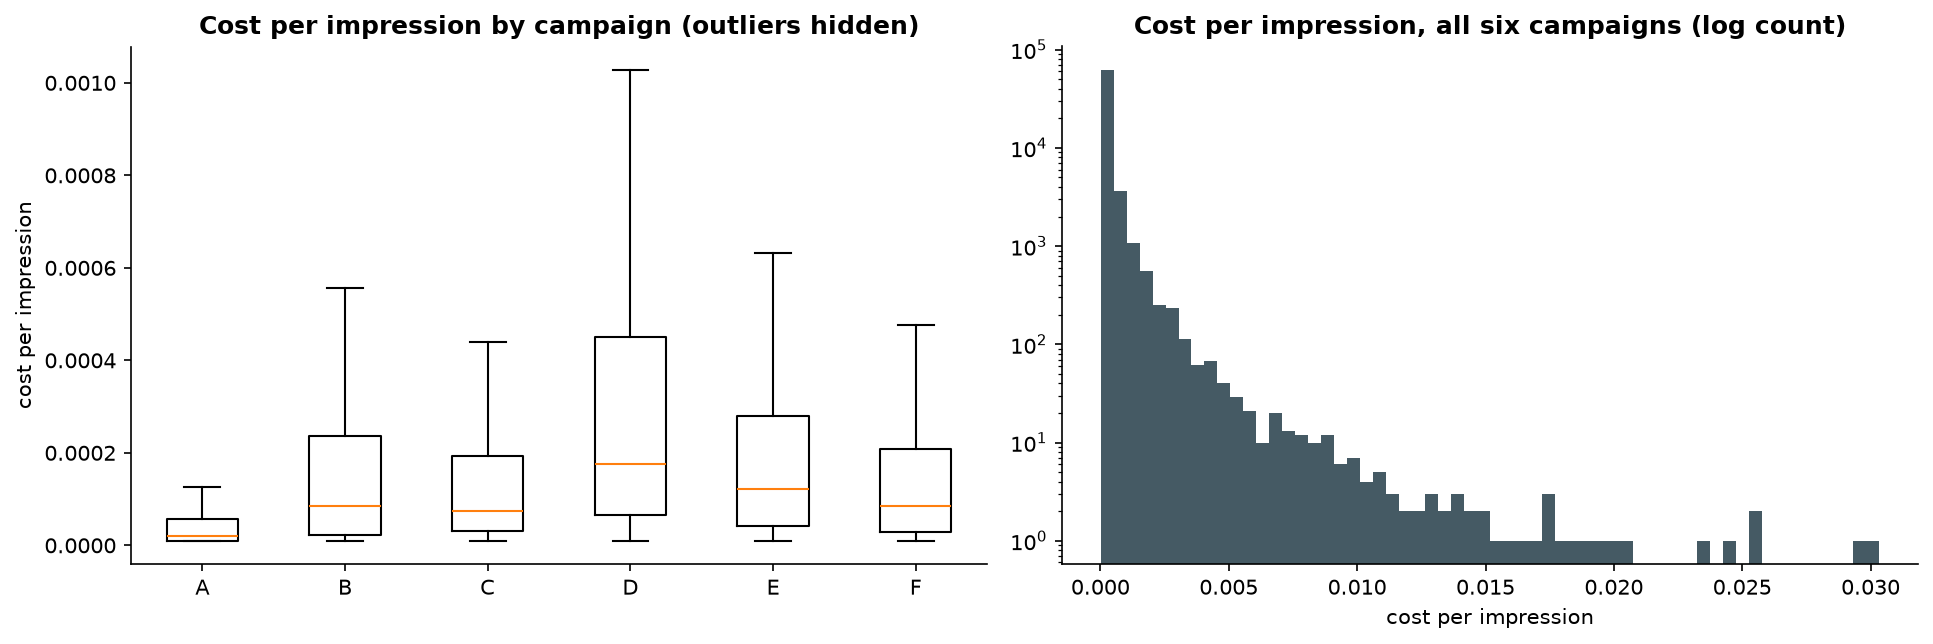

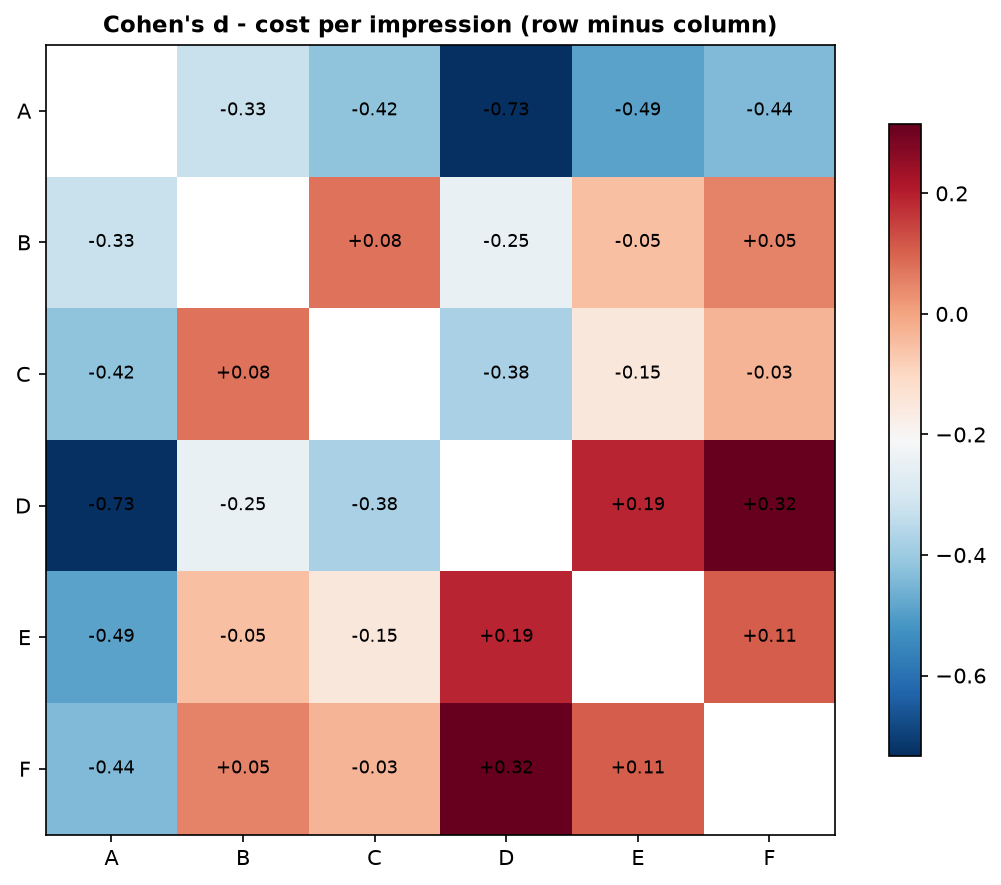

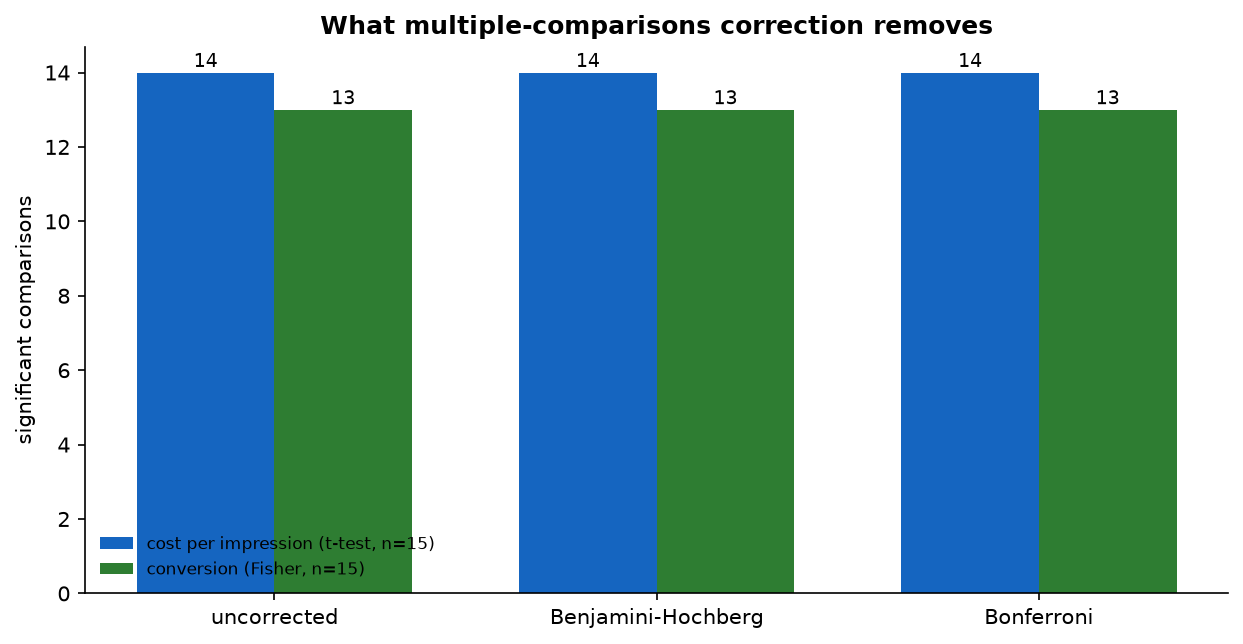

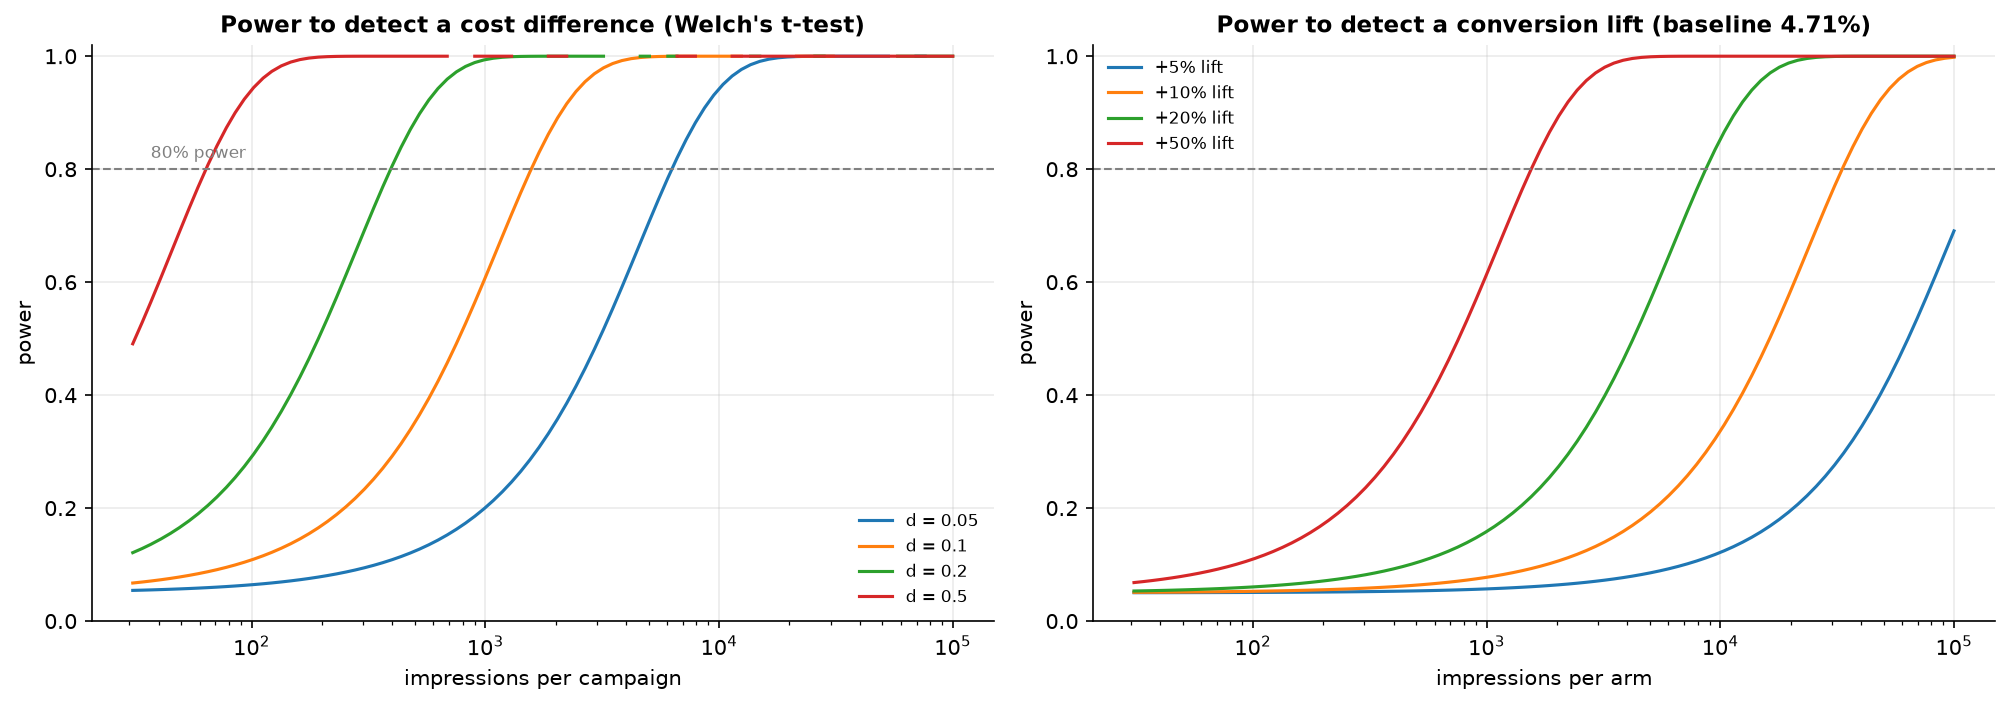

In [12]:
%matplotlib inline
from IPython.display import Image, display
for f in ("figures/exploration_overview.png", "figures/cost_distributions.png",
          "figures/heatmap_cohens_d.png", "figures/correction_effect.png",
          "figures/power_curves.png"):
    display(Image(filename=f))

## Conclusions

1. **Conversion rates differ by a factor of four** (2.0% to 8.3%) and the gaps
   survive every correction. Those are real.
2. **Cost differences mostly are not worth acting on.** Fourteen of fifteen are
   significant; six of those have a negligible effect size. Only Campaign A
   against Campaign D reaches a medium effect.
3. **Two pairs are statistically indistinguishable** &mdash; B/E and C/D. That
   turns a ranking of six into two strong campaigns and two weak ones, which is
   the honest shape of the result.
4. **Correction changed nothing at this sample size and a great deal at pilot
   size**, where Bonferroni withdrew three of seven findings.
5. **The data is observational.** Campaigns were not randomly assigned to
   audiences, so none of this establishes that moving budget reproduces the gap.

The recommendation, with the budget table and the sizing for a proper test, is in
`executive_memo.md`.